In [13]:
import os
import json
import gzip
import itertools
from itertools import chain
import pandas as pd
import numpy as np
import networkx as nx
from collections import defaultdict

import scipy.sparse as spsparse
import scipy.stats as spstats

from sklearn.preprocessing import normalize

from statsmodels.stats.multitest import multipletests as holm
import statsmodels.api as sm

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
import matplotlib.transforms as mtransforms
import seaborn as sns

import pyscisci.all as pyscisci

import scienceplots
plt.style.use('science')


In [6]:
# set this path to where the OpenAlex database is stored
path2openalex = '/Users/hgt6rn/Documents/DataSets/OpenAlex'

# set this path to where the processed data is stored:
path2countrydata = "CountryData"


# Create the random countries null model

In [ ]:
from pyscisci.datasource.OpenAlex import OpenAlex

myoa = OpenAlex(path2database=path2oa, database_extension='csv.gz')


pub2doctype = pd.read_csv(os.path.join(path2oa, 'pub2doctype.csv.gz'))
pub2year = pd.read_csv(os.path.join(path2oa, 'pub2year.csv.gz'))

pub2doctype = pub2doctype[pub2doctype['DocType']=='article']
pub2doctype = pub2doctype.merge(pub2year, how='inner', on='PublicationId')
pub2doctype.dropna(inplace=True)

print(pub2doctype['PublicationId'].nunique(), "Articles")
pub2doctype = pub2doctype[np.logical_and(pub2doctype['Year'] >= 1990, pub2doctype['Year'] <= 2023)]
print(pub2doctype['PublicationId'].nunique(), "Articles in timespan")


pub2year = {pid:y for pid, y in pub2doctype[['PublicationId', 'Year']].values}
print(len(pub2year))

pubarticles = np.sort(pub2doctype['PublicationId'].values)
print(pubarticles.shape)

pub2country = pd.read_csv(os.path.join(path2oa, 'precomputed_data', 'oa_pub2country.csv.gz'))
pub2country['Year'] = [pub2year.get(pid, None) for pid in pub2country['PublicationId'].values]
pub2country['RandomCountry'] = pub2country.groupby('Year', group_keys=False)['Country'].apply(lambda g: g.sample(frac=1)).reset_index(drop=True)

aff_df = myoa.load_affiliations(columns = ['AffiliationId', 'Country'])
aff_df.dropna(inplace=True)
aff_df.reset_index(drop=True, inplace=True)

focus_affs = np.sort(aff_df['AffiliationId'].values)

paa_df = myoa.load_publicationauthoraffiliation(columns=['PublicationId', 'AuthorId', 'AffiliationId'],
                                                filter_dict = {'AffiliationId':focus_affs, 'PublicationId':pubarticles})

paa_df['Year'] = [pub2year.get(pid, None) for pid in paa_df['PublicationId'].values]
paa_df.dropna(inplace=True)

print(paa_df['PublicationId'].nunique(), "Articles in timespan with affiliation information")

print(paa_df.shape)

pub2authors = defaultdict(set)
pub2aff = defaultdict(set)
for pid, aid, aff in paa_df[['PublicationId', 'AuthorId', 'AffiliationId']].values:
    pub2authors[pid].add(aid)
    pub2aff[pid].add(aff)
    
print(len(pub2authors), len(pub2aff))


pub2ref = []

pfiles = os.listdir(os.path.join(path2oa, 'pub2ref'))
print(len(pfiles))

for ifname in range(len(pfiles)):
    fname = pfiles[ifname]
    if '.csv.gz' in fname:
        df = pd.read_csv(os.path.join(path2oa, 'pub2ref', fname))
        
        df['CitedYear'] = [pub2year.get(pid, None) for pid in df['CitedPublicationId'].values]
        df.dropna(inplace=True)
        #df = df.loc[df['CitedYear'] <= 2017]
        
        df['CitingYear'] = [pub2year.get(pid, None) for pid in df['CitingPublicationId'].values]
        df.dropna(inplace=True)
        
        df = df.loc[df['CitingYear'] >= df['CitedYear']]
        df = df.loc[df['CitingYear'] <=  df['CitedYear'].values + 5]
        

        noselfciteauthor = np.array([len(pub2authors[citingpid] & pub2authors[citedpid]) == 0 for citingpid, citedpid in df[['CitingPublicationId', 'CitedPublicationId']].values])
        df = df.loc[noselfciteauthor]
        
        noselfciteaff = np.array([len(pub2aff[citingpid] & pub2aff[citedpid]) == 0 for citingpid, citedpid in df[['CitingPublicationId', 'CitedPublicationId']].values])
        df = df.loc[noselfciteaff]
        
        pub2ref.append(df[['CitingPublicationId', 'CitingYear', 'CitedPublicationId', 'CitedYear']])
    if ifname % 50 == 0:
        print(ifname)

pub2ref = pd.concat(pub2ref)
pub2ref.drop_duplicates(subset=['CitingPublicationId', 'CitedPublicationId'], inplace=True)

pub2ref= pub2ref[pub2ref['CitedYear'] == 2017]

pub2ref = pub2ref.merge(pub2country[['PublicationId', 'RandomCountry']], how='left', left_on = 'CitingPublicationId', right_on='PublicationId')
del pub2ref['PublicationId']
pub2ref.rename(columns={'RandomCountry':'CitingCountry'}, inplace=True)

pub2ref = pub2ref.merge(pub2country[['PublicationId', 'RandomCountry']], how='left', left_on = 'CitedPublicationId', right_on='PublicationId')
del pub2ref['PublicationId']
pub2ref.rename(columns={'RandomCountry':'CitedCountry'}, inplace=True)

pub2ref.to_csv(os.path.join(path2oa, 'precomputed_data', 'random_country_citation_network2017.csv.gz'), compression='gzip', index=False, header=True)

print(pub2ref.shape[0], "Final number of reference relationships remaining with countries")
print(pub2ref.nunique(), "Publications remaining with countries")

# Create the random citation null model

In [ ]:
from pyscisci.datasource.OpenAlex import OpenAlex

myoa = OpenAlex(path2database=path2oa, database_extension='csv.gz')


pub2doctype = pd.read_csv(os.path.join(path2oa, 'pub2doctype.csv.gz'))
pub2year = pd.read_csv(os.path.join(path2oa, 'pub2year.csv.gz'))

pub2doctype = pub2doctype[pub2doctype['DocType']=='article']
pub2doctype = pub2doctype.merge(pub2year, how='inner', on='PublicationId')
pub2doctype.dropna(inplace=True)

print(pub2doctype['PublicationId'].nunique(), "Articles")
pub2doctype = pub2doctype[np.logical_and(pub2doctype['Year'] >= 1990, pub2doctype['Year'] <= 2023)]
print(pub2doctype['PublicationId'].nunique(), "Articles in timespan")


pub2year = {pid:y for pid, y in pub2doctype[['PublicationId', 'Year']].values}
print(len(pub2year))

pubarticles = np.sort(pub2doctype['PublicationId'].values)
print(pubarticles.shape)

pub2country = pd.read_csv(os.path.join(path2oa, 'precomputed_data', 'oa_pub2country.csv.gz'))
pub2country['Year'] = [pub2year.get(pid, None) for pid in pub2country['PublicationId'].values]


aff_df = myoa.load_affiliations(columns = ['AffiliationId', 'Country'])
aff_df.dropna(inplace=True)
aff_df.reset_index(drop=True, inplace=True)

focus_affs = np.sort(aff_df['AffiliationId'].values)

paa_df = myoa.load_publicationauthoraffiliation(columns=['PublicationId', 'AuthorId', 'AffiliationId'],
                                                filter_dict = {'AffiliationId':focus_affs, 'PublicationId':pubarticles})

paa_df['Year'] = [pub2year.get(pid, None) for pid in paa_df['PublicationId'].values]
paa_df.dropna(inplace=True)

print(paa_df['PublicationId'].nunique(), "Articles in timespan with affiliation information")

print(paa_df.shape)

pub2authors = defaultdict(set)
pub2aff = defaultdict(set)
for pid, aid, aff in paa_df[['PublicationId', 'AuthorId', 'AffiliationId']].values:
    pub2authors[pid].add(aid)
    pub2aff[pid].add(aff)
    
print(len(pub2authors), len(pub2aff))


pub2ref = []

pfiles = os.listdir(os.path.join(path2oa, 'pub2ref'))
print(len(pfiles))

for ifname in range(len(pfiles)):
    fname = pfiles[ifname]
    if '.csv.gz' in fname:
        df = pd.read_csv(os.path.join(path2oa, 'pub2ref', fname))
        
        df['CitedYear'] = [pub2year.get(pid, None) for pid in df['CitedPublicationId'].values]
        df.dropna(inplace=True)
        #df = df.loc[df['CitedYear'] <= 2017]
        
        df['CitingYear'] = [pub2year.get(pid, None) for pid in df['CitingPublicationId'].values]
        df.dropna(inplace=True)
        
        df = df.loc[df['CitingYear'] >= df['CitedYear']]
        df = df.loc[df['CitingYear'] <=  df['CitedYear'].values + 5]
        

        noselfciteauthor = np.array([len(pub2authors[citingpid] & pub2authors[citedpid]) == 0 for citingpid, citedpid in df[['CitingPublicationId', 'CitedPublicationId']].values])
        df = df.loc[noselfciteauthor]
        
        noselfciteaff = np.array([len(pub2aff[citingpid] & pub2aff[citedpid]) == 0 for citingpid, citedpid in df[['CitingPublicationId', 'CitedPublicationId']].values])
        df = df.loc[noselfciteaff]
        
        pub2ref.append(df[['CitingPublicationId', 'CitingYear', 'CitedPublicationId', 'CitedYear']])
    if ifname % 50 == 0:
        print(ifname)

pub2ref = pd.concat(pub2ref)
pub2ref.drop_duplicates(subset=['CitingPublicationId', 'CitedPublicationId'], inplace=True)

# do the randomizatoin
pub2ref['CitedPublicationId'] = pub2ref.groupby(['CitedYear', 'CitingYear'], group_keys=False)['CitedPublicationId'].apply(lambda g: g.sample(frac=1)).reset_index(drop=True)

pub2ref = pub2ref.merge(pub2country[['PublicationId', 'Country']], how='left', left_on = 'CitingPublicationId', right_on='PublicationId')
del pub2ref['PublicationId']
pub2ref.rename(columns={'Country':'CitingCountry'}, inplace=True)

pub2ref = pub2ref.merge(pub2country[['PublicationId', 'Country']], how='left', left_on = 'CitedPublicationId', right_on='PublicationId')
del pub2ref['PublicationId']
pub2ref.rename(columns={'Country':'CitedCountry'}, inplace=True)

pub2ref.to_csv(os.path.join(path2oa, 'precomputed_data', 'oa_countrycites_noselfauthoraff_randgraph.csv.gz'), compression='gzip', index=False, header=True)

print(pub2ref.shape[0], "Final number of reference relationships remaining with countries")
print(pub2ref.nunique(), "Publications remaining with countries")


randcountry.dropna(inplace=True)
print(randcountry.shape)

randcites = randcountry.groupby(['CitedPublicationId', 'CitedCountry', 'CitedYear', 'CitingCountry'], as_index=False)['CitingPublicationId'].nunique()
randcites.rename(columns={'CitingPublicationId':'CountryCitations'}, inplace=True)

rand_cites_auc = []
def country_auc(citedf):
    for cited_c in citedf['CitedCountry'].unique():
        x = citedf[citedf['CitedCountry'] == cited_c]['CountryCitations'].values
        y = citedf['CountryCitations'].values
        auc, delongcov = pyscisci.fast_delong(x, y)
        cname, y = citedf.name
        rand_cites_auc.append([cname, y, cited_c, auc, delongcov, x.shape[0]])

randcites.groupby(['CitingCountry', 'CitedYear'])[['CitedCountry', 'CountryCitations']].apply(country_auc)
rand_cites_auc = pd.DataFrame(rand_cites_auc, columns=['CitingCountry', 'CitedYear', 'CitedCountry', 'AUC', 'Cov', 'N'])

print(rand_cites_auc.shape)

rand_cites_auc.read_csv('/Users/hgt6rn/Downloads/oa_countrycites_noselfauthoraff_randgraph_auc.csv.gz')


# Compare the resulting networks

In [8]:
# lets focus on the citation without the same organization and self citations

country_auc_df = pd.read_csv(os.path.join(path2countrydata, 'oa_countrycites_nosameorg_auc.csv.gz'))

country_auc_df = country_auc_df[country_auc_df['N']>=50]

country_auc_df['Zscore'] = (country_auc_df['AUC'] - 0.5)/np.sqrt(country_auc_df['Cov'])
country_auc_df['pvalue'] = spstats.norm.sf(np.abs(country_auc_df['Zscore'].values))

def reject_holm(pvalues):
    reject, pvalues, _, _ = holm(pvalues, alpha=0.01, method='hs', is_sorted=False, returnsorted=False)
    return reject
country_auc_df['Significant'] = country_auc_df.groupby('CitedYear')['pvalue'].transform(reject_holm)

net_auc = country_auc_df[country_auc_df['CitingCountry'] != country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
net_auc = net_auc[net_auc['Significant']]
self_auc = country_auc_df[country_auc_df['CitingCountry'] == country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
self_auc = self_auc[self_auc['Significant']]

syear, eyear = 1990, 2017
net_auc = net_auc[net_auc['CitedYear'] >= syear]
net_auc = net_auc[net_auc['CitedYear'] <= eyear]

comm2country = {0:['AE', 'BD', 'CN', 'CY', 'DZ', 'EG', 'ID', 'IN', 'IQ', 'IR', 'JO', 'KH', 'KR', 'KW', 'MA', 'MY', 'OM', 'PK', 'QA', 'SA', 'SG', 'TH', 'TN', 'TR', 'TW', 'VN'],
1:['AR', 'BN', 'BO', 'BR', 'BW', 'BY', 'CL', 'CM', 'CO', 'CR', 'GE', 'HK', 'HR', 'LU', 'MZ', 'NC', 'PA', 'PE', 'RU', 'SJ', 'ST', 'UY', 'VE'],
2:['AT', 'BE', 'CA', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HU', 'IE', 'IL', 'IS', 'IT', 'JP', 'MX', 'NL', 'NO', 'NP', 'NZ', 'PH', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK'],
3:['AU', 'CH', 'GB', 'US'],
4:['BH', 'ET', 'GH', 'KE', 'MW', 'NG', 'TZ', 'UG', 'ZA', 'ZM', 'ZW']}

country2comm = {c:ci for ci,clist in comm2country.items() for c in clist}
poscountrylist = sorted(list(country2comm.keys()))

connected_countries = np.sort(np.unique(net_auc[net_auc['Zscore'] > 0][['CitingCountry', 'CitedCountry']].values.flatten()))

In [53]:
syear, eyear = 1990, 2017
net_auc = net_auc[net_auc['CitedYear'] >= syear]
net_auc = net_auc[net_auc['CitedYear'] <= eyear]
cumulative_net = net_auc.sort_values('CitedYear').drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')


print(cumulative_net.shape, "edges")
cum_connected_countries = np.sort(np.unique(cumulative_net[['CitingCountry', 'CitedCountry']].values.flatten()))
print(cum_connected_countries.shape, "countries")


(2007, 9) edges
(147,) countries


In [29]:
randcountry = pd.read_csv('/Users/hgt6rn/Downloads/random_country_citation_network2017.csv.gz')
print(randcountry.shape)

randcountry.dropna(inplace=True)
print(randcountry.shape)

randcites = randcountry.groupby(['CitedPublicationId', 'CitedCountry', 'CitedYear', 'CitingCountry'], as_index=False)['CitingPublicationId'].nunique()
randcites.rename(columns={'CitingPublicationId':'CountryCitations'}, inplace=True)


/var/folders/69/w28tw6xx26nd7x4yv_sh2mgm0000gp/T/ipykernel_98739/2451724909.py:1: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  randcountry = pd.read_csv('/Users/hgt6rn/Downloads/random_country_citation_network2017.csv.gz')


(73602998, 6)
(47885117, 6)


In [30]:


rand_country_auc = []
def country_auc(citedf):
    for cited_c in citedf['CitedCountry'].unique():
        x = citedf[citedf['CitedCountry'] == cited_c]['CountryCitations'].values
        y = citedf['CountryCitations'].values
        auc, delongcov = pyscisci.fast_delong(x, y)
        cname, y = citedf.name
        rand_country_auc.append([cname, y, cited_c, auc, delongcov, x.shape[0]])

randcites.groupby(['CitingCountry', 'CitedYear'])[['CitedCountry', 'CountryCitations']].apply(country_auc)
rand_country_auc = pd.DataFrame(rand_country_auc, columns=['CitingCountry', 'CitedYear', 'CitedCountry', 'AUC', 'Cov', 'N'])

print(rand_country_auc.shape)

(30030, 6)


In [33]:
rand_country_auc['Zscore'] = (rand_country_auc['AUC'] - 0.5)/np.sqrt(rand_country_auc['Cov'])

    
rand_country_auc = rand_country_auc[rand_country_auc['N']>=50].reset_index(drop=True)


rand_country_auc['pvalue'] = spstats.norm.sf(np.abs(rand_country_auc['Zscore'].values))

rand_country_auc = rand_country_auc[rand_country_auc['pvalue'] > 0]

def reject_holm(pvalues):
    reject, pvalues, _, _ = holm(pvalues, alpha=0.01, method='hs', is_sorted=False, returnsorted=False)
    return reject
rand_country_auc['Significant'] = rand_country_auc.groupby('CitedYear')['pvalue'].transform(reject_holm)

rand_country_auc = rand_country_auc[rand_country_auc['CitingCountry'] != rand_country_auc['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
rand_country_auc = rand_country_auc[rand_country_auc['Significant']]
rand_country_auc


,CitingCountry,CitedYear,CitedCountry,AUC,Cov,N,Zscore,pvalue,Significant
228,ZM,2017.0,AR,0.494022,3.796714e-07,50,-9.701195,1.489933e-22,True
244,CI,2017.0,AT,0.491028,5.378567e-07,50,-12.233877,1.024598e-34,True
281,KH,2017.0,AT,0.493227,4.572082e-07,54,-10.017276,6.399085e-24,True
288,LU,2017.0,AT,0.485641,4.029705e-07,114,-22.620024,1.376657e-113,True
291,MD,2017.0,AT,0.492815,4.171090e-07,53,-11.124932,4.743935e-29,True
...,...,...,...,...,...,...,...,...,...
9085,SE,2017.0,US,0.494768,8.656912e-07,60974,-5.622826,9.392954e-09,True
9104,TR,2017.0,US,0.495528,8.398456e-07,66692,-4.880036,5.303323e-07,True
9106,TW,2017.0,US,0.494274,9.059346e-07,54802,-6.015683,8.956494e-10,True
9462,MT,2017.0,ZA,0.493455,4.359245e-07,54,-9.913292,1.822189e-23,True


In [54]:
syear, eyear = 1990, 2017
rand_country_auc = rand_country_auc[rand_country_auc['CitedYear'] >= syear]
rand_country_auc = rand_country_auc[rand_country_auc['CitedYear'] <= eyear]
rand_country_cumulative_net = rand_country_auc.sort_values('CitedYear').drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')


print(rand_country_cumulative_net.shape, "edges")
rand_cum_connected_countries = np.sort(np.unique(rand_country_cumulative_net[['CitingCountry', 'CitedCountry']].values.flatten()))
print(rand_cum_connected_countries.shape, "countries")


(291, 9) edges
(102,) countries


In [26]:
randcitegraph = pd.read_csv('/Users/hgt6rn/Downloads/oa_countrycites_noselfauthoraff_randgraph_auc.csv.gz')

randcitegraph['Zscore'] = (rand_country_auc['AUC'] - 0.5)/np.sqrt(rand_country_auc['Cov'])

    
randcitegraph = randcitegraph[randcitegraph['N']>=50].reset_index(drop=True)


randcitegraph['pvalue'] = spstats.norm.sf(np.abs(randcitegraph['Zscore'].values))

randcitegraph = randcitegraph[randcitegraph['pvalue'] > 0]

def reject_holm(pvalues):
    reject, pvalues, _, _ = holm(pvalues, alpha=0.01, method='hs', is_sorted=False, returnsorted=False)
    return reject
randcitegraph['Significant'] = randcitegraph.groupby('CitedYear')['pvalue'].transform(reject_holm)

randcitegraph = randcitegraph[randcitegraph['CitingCountry'] != randcitegraph['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
randcitegraph = randcitegraph[randcitegraph['Significant']]
randcitegraph
                     

,CitingCountry,CitedYear,CitedCountry,AUC,Cov,N,Zscore,pvalue,Significant
5,AE,1989,US,0.500000,0.000000e+00,114,2.590365,4.793717e-03,True
7,AE,1991,US,0.499538,7.899501e-06,216,-12.233877,1.024598e-34,True
111,AE,2004,DE,0.501404,1.338594e-05,367,3.869990,5.441996e-05,True
129,AE,2005,BR,0.496974,3.499100e-05,85,-4.370618,6.194764e-06,True
275,AE,2009,MX,0.485326,4.058637e-07,81,-4.534545,2.886390e-06,True
325,AE,2010,SG,0.512579,8.244449e-05,170,6.408247,7.360120e-11,True
327,AE,2010,TR,0.489640,2.136910e-05,153,-9.337310,4.940625e-21,True
358,AE,2011,JP,0.502834,1.126904e-05,851,-11.050911,1.085009e-28,True
408,AE,2012,MY,0.486476,2.510486e-05,140,-14.732256,2.000618e-49,True
439,AE,2013,DE,0.502523,5.768893e-06,2227,-4.116420,1.924014e-05,True


In [55]:
syear, eyear = 1990, 2017
randcitegraph = randcitegraph[randcitegraph['CitedYear'] >= syear]
randcitegraph = randcitegraph[randcitegraph['CitedYear'] <= eyear]
rand_cumulative_net = randcitegraph.sort_values('CitedYear').drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')


print(rand_cumulative_net.shape, "edges")
rand_cum_connected_countries = np.sort(np.unique(rand_cumulative_net[['CitingCountry', 'CitedCountry']].values.flatten()))
print(rand_cum_connected_countries.shape, "countries")


(15, 9) edges
(17,) countries


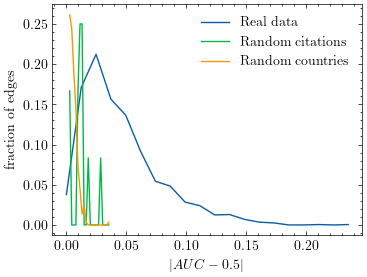

In [50]:
real_dist,  auc_bin= np.histogram(np.abs(cumulative_net['AUC'].values - 0.5), bins=20)
randc_dist, rc_auc_bin = np.histogram(np.abs(rand_country_cumulative_net['AUC'].values - 0.5), bins=20)
randnet_dist, rn_auc_bin = np.histogram(np.abs(rand_cumulative_net['AUC'].values - 0.5), bins=rc_auc_bin)

fig, ax = plt.subplots(1,1,figsize=(4,3))

ax.plot(auc_bin[:-1], real_dist/real_dist.sum(), label='Real data')

ax.plot(rc_auc_bin[:-1], randnet_dist/randnet_dist.sum(), label='Random citations')

ax.plot(rc_auc_bin[:-1], randc_dist/randc_dist.sum(), label='Random countries')

ax.set_xlabel("$| AUC - 0.5 |$")
ax.set_ylabel("fraction of edges")
plt.legend()
plt.savefig('random_network_auc_dist.png')

plt.show()